# Paper-quality figures: impulse responses and decompositions

In [1]:
# Setup: install the toolkit when running on Google Colab, and a plotting style
import sys

if "google.colab" in sys.modules:
    %pip install -q "econts[book] @ git+https://github.com/hmorao95/econ-time-series-manual"

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

Figures in a paper follow different rules from exploratory plots: they are
read in print, in grey, at a small size, next to a caption. This chapter
draws the standard figures of an SVAR paper with
[housestyle](https://github.com/hmorao95/housestyle), a small package that
reproduces in matplotlib the MATLAB figure style used in a series of SVAR
papers on shipping disruptions, so Python and MATLAB figures can sit side by
side in one paper.

In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import housestyle as hs
from econts import load

## The model: a small oil-shock SVAR

Monthly US data, 1990–2019: the real oil price, industrial production and
CPI in log differences × 100, and the unemployment rate in levels. The oil
price is ordered first, so an oil shock can move everything else on impact
but nothing else moves the oil price within the month (a recursive,
Cholesky identification). Twelve lags.

In [3]:
oil = load("DCOILBRENTEU").resample("MS").mean()  # daily -> monthly mean
cpi, ip, u = load("CPIAUCSL"), load("INDPRO"), load("UNRATE")
data = (
    pd.DataFrame(
        {
            "oil": 100 * np.log(oil / cpi).diff(),  # real oil price growth
            "ip": 100 * np.log(ip).diff(),
            "cpi": 100 * np.log(cpi).diff(),
            "u": u,
        }
    )
    .loc["1990":"2019"]
    .asfreq("MS")
)

var = sm.tsa.VAR(data).fit(12)
H = 24
irf = var.irf(H)

Responses of variables in growth rates are **cumulated** to give the effect
on the level; the unemployment rate is already a level. The shock is scaled
to raise the real oil price by 10% on impact, a more readable unit than "one
standard deviation". For simplicity the bands are rescaled by the same
factor as the point estimate; a stricter version would normalize each Monte
Carlo draw by its own impact response.

In [4]:
cumulate = np.array([True, True, True, False])  # oil, ip, cpi | u
point = np.where(cumulate, irf.orth_cum_effects[:, :, 0], irf.orth_irfs[:, :, 0])
scale = 10 / point[0, 0]

rng = np.random.default_rng(0)  # 68% Monte Carlo bands
lo_c, hi_c = irf.cum_errband_mc(orth=True, repl=500, signif=0.32, rng=rng)
lo_l, hi_l = irf.errband_mc(orth=True, repl=500, signif=0.32, rng=rng)
lo = np.where(cumulate, lo_c[:, :, 0], lo_l[:, :, 0])
hi = np.where(cumulate, hi_c[:, :, 0], hi_l[:, :, 0])

med, lo, hi = point * scale, lo * scale, hi * scale
print(
    pd.DataFrame(med[[0, 6, 12, 24]], index=[0, 6, 12, 24], columns=data.columns).round(
        2
    )
)

      oil    ip   cpi     u
0   10.00  0.03  0.13  0.00
6    9.12  0.20  0.31 -0.03
12   9.45  0.01  0.32  0.00
24   7.93 -0.15  0.27  0.07


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.svar import irf_with_bands
    
    irf = irf_with_bands(var, shock=0, horizon=24, cumulate=[True, True, True, False], impact=10)
```

A 10% oil price increase raises the CPI by about 0.3% within six months
and leaves real activity almost unchanged: industrial production moves by a
fraction of a percent, unemployment by hundredths of a point. That is the
familiar finding that oil price *changes* mix supply and demand shocks; a
paper would separate them (Kilian, 2009).

## Impulse responses in a grid

`hs.figure(rows, cols)` sets up the MATLAB-sized grid; `hs.irf` draws a
panel: black median, band over it, zero line, labels. The horizon starts at
0 (impact), so text quoting h = 0, 6, 12 matches the axis.

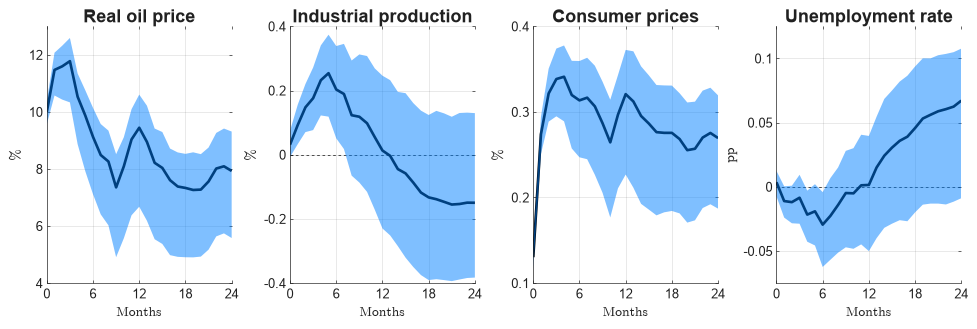

In [5]:
names = [
    "Real oil price",
    "Industrial production",
    "Consumer prices",
    "Unemployment rate",
]
units = ["%", "%", "%", "pp"]
h = np.arange(H + 1)

fig, axes = hs.figure(1, 4)
for k, ax in enumerate(axes):
    ax.set_xticks(range(0, H + 1, 6))
    hs.irf(ax, h, med[:, k], lo[:, k], hi[:, k], names[k], units[k], "Months")

In a paper the script ends with the export, which writes a 300 dpi PNG (or a
PDF, by suffix) cropped to the content:

```py
hs.outdir("figures")  # once per script
hs.export(fig, "irf_oil_baseline")
```

## Comparing specifications

Robustness figures overlay alternatives on the baseline and its band. Draw
the baseline, then the band, then the alternatives, then `hs.finish` for
labels and the zero line; the legend goes in one panel.

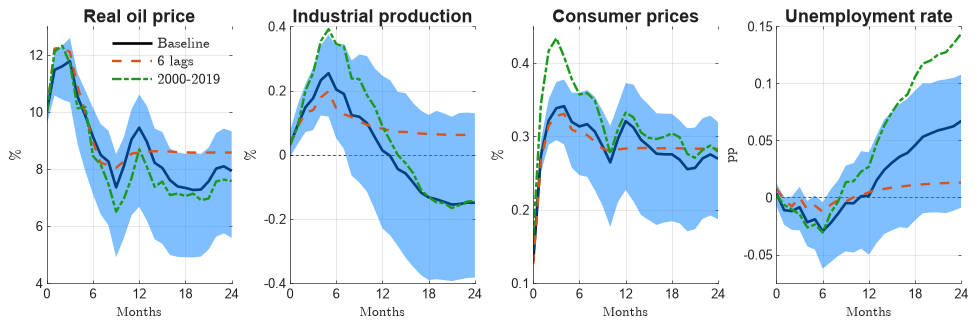

In [6]:
def point_irf(data, lags):
    """Point responses to a 10% oil shock, cumulated like the baseline."""
    r = sm.tsa.VAR(data).fit(lags).irf(H)
    p = np.where(cumulate, r.orth_cum_effects[:, :, 0], r.orth_irfs[:, :, 0])
    return p * 10 / p[0, 0]


alternatives = {
    "6 lags": point_irf(data, 6),
    "2000-2019": point_irf(data.loc["2000":], 12),
}

fig, axes = hs.figure(1, 4)
for k, ax in enumerate(axes):
    h1 = hs.line(ax, h, med[:, k], 1)  # black solid
    hs.band(ax, h, lo[:, k], hi[:, k])
    h2 = hs.line(ax, h, alternatives["6 lags"][:, k], 2)  # orange dashed
    h3 = hs.line(ax, h, alternatives["2000-2019"][:, k], 3)  # green dash-dot
    ax.set_xlim(0, H)
    ax.set_xticks(range(0, H + 1, 6))
    hs.finish(ax, names[k], units[k], "Months")
hs.legend(axes[0], [h1, h2, h3], ["Baseline", "6 lags", "2000-2019"], loc="upper right")

## Time series with shaded episodes and events

One observed series is drawn in the MATLAB blue (`hs.line(..., "data")`);
`hs.shade` adds grey episodes behind the data and `hs.event` labels a point.
Here, the real oil price with NBER recessions:

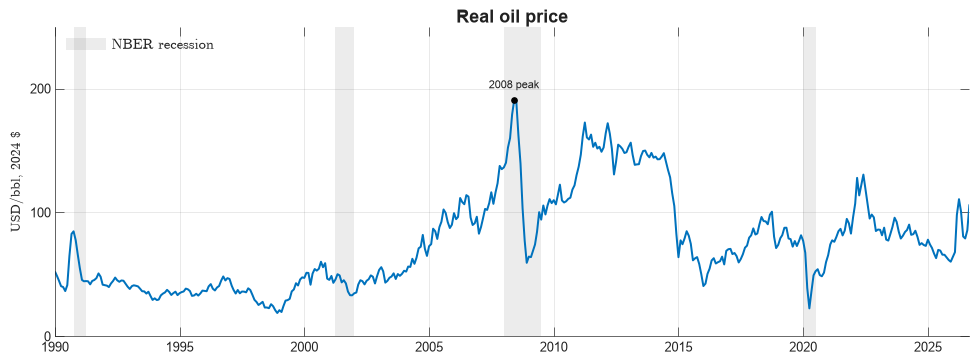

In [7]:
real_oil = (oil / cpi * cpi["2024"].mean()).loc["1990":].dropna()
rec = load("USRECQ").to_period("Q").loc["1990":]
starts = rec.index[(rec == 1) & (rec.shift(1, fill_value=0) == 0)]
ends = rec.index[(rec == 1) & (rec.shift(-1, fill_value=0) == 0)]

fig, ax = hs.figure(1, 1, 380)
hs.line(ax, real_oil.index, real_oil.to_numpy(), "data")
for s, e in zip(starts, ends):
    shade = hs.shade(ax, s.start_time, e.end_time, label="Recession")
ax.set_xlim(real_oil.index[0], real_oil.index[-1])
ax.set_ylim(0, 250)
peak = real_oil.loc["2008"].idxmax()
hs.event(ax, peak, real_oil[peak], "2008 peak")
hs.finish(ax, "Real oil price", "USD/bbl, 2024 \\$")
hs.legend(ax, [shade], ["NBER recession"], loc="upper left")

## Historical decomposition

A historical decomposition splits each variable, period by period, into the
contribution of each structural shock plus a deterministic part (constant
and initial conditions). With residuals $u_t$, the Cholesky factor $P$ of
their covariance and the orthogonalized MA coefficients $\Theta_j$, the
shocks are $\varepsilon_t = P^{-1}u_t$ and shock $k$ contributes
$\sum_{j=0}^{t}\Theta_j[i,k]\,\varepsilon_{t-j,k}$ to variable $i$ at $t$.

In [8]:
eps = var.resid.to_numpy() @ np.linalg.inv(np.linalg.cholesky(var.sigma_u)).T
T, n = eps.shape
theta = var.orth_ma_rep(maxn=T - 1)  # (T, n, n)
contrib = np.zeros((T, n, n))  # time, variable, shock
for t in range(T):
    contrib[t] = np.einsum("jik,jk->ik", theta[: t + 1], eps[t::-1])

dates = var.resid.index
actual = data.loc[dates].to_numpy()
deterministic = actual - contrib.sum(axis=2)
print("adds up:", np.allclose(deterministic + contrib.sum(axis=2), actual))

adds up: True


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.svar import historical_decomposition
    
    contributions, deterministic = historical_decomposition(var)
```

The decomposition of the unemployment rate around the Great Recession, as
stacked bars with the total (actual minus deterministic part) on top:

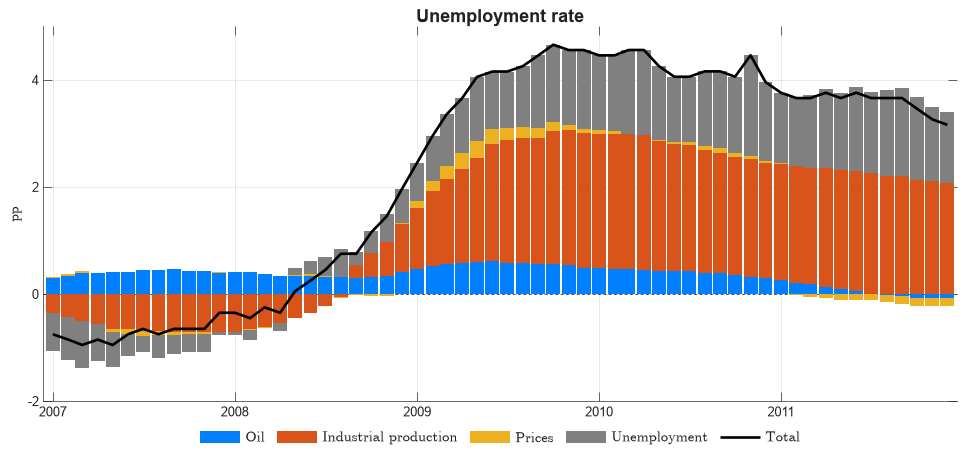

In [9]:
window = (dates >= "2007-01-01") & (dates <= "2011-12-01")
x = dates[window].to_numpy()
Y = contrib[window, 3, :]  # unemployment, all shocks
total = Y.sum(axis=1)

fig, ax = hs.figure(1, 1, 460)
bars = hs.bars(ax, x, Y)
h_total = hs.line(ax, x, total, 1)
ax.set_xlim(x[0] - np.timedelta64(20, "D"), x[-1] + np.timedelta64(20, "D"))
hs.finish(ax, "Unemployment rate", "pp")
hs.legend(
    ax,
    [*bars, h_total],
    ["Oil", "Industrial production", "Prices", "Unemployment", "Total"],
    outside="south",
)

Of the 4.5-point rise in unemployment in 2008–09, the model attributes most
to industrial production shocks and to unemployment's own shocks; oil shocks
account for about half a point, consistent with the small impulse responses
above.

## Without housestyle

The essentials take a few lines of plain matplotlib, if you prefer no
dependency:

```py
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "axes.grid": True,
        "grid.alpha": 0.15,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "axes.titleweight": "bold",
        "mathtext.fontset": "cm",
        "savefig.dpi": 300,
    }
)
fig, ax = plt.subplots()
ax.plot(h, med[:, 0], color="k", lw=2)
ax.fill_between(h, lo[:, 0], hi[:, 0], color=(0, 0.5, 1), alpha=0.5, lw=0)
ax.axhline(0, color="k", ls="--", lw=0.5, zorder=0)
fig.savefig("irf.png", bbox_inches="tight", facecolor="white")
```

## Pitfalls

* **Cumulate the right variables.** Responses of variables in differences
  are cumulated to get levels; cumulating a variable already in levels (the
  unemployment rate) produces nonsense.
* **State the shock size and the band.** "68% bands, shock normalized to a
  10% oil price increase" belongs in the caption.
* **Same axes across a comparison**, different axes across variables:
  comparing specifications needs identical y-limits within a panel, not
  across panels.
* **Bands are about the estimate, not the identification.** A tight band
  around a recursive SVAR says nothing about whether the ordering is right.

## Summary

* Point estimate **black**, band **translucent blue over it**, dashed zero
  line only when zero is in range.
* Tell series apart by **line style as well as color** (solid, dashed,
  dash-dot): figures must survive grey print and colorblind readers.
  More than four series: use small multiples.
* **No overall title**: the LaTeX caption explains the figure. Panel
  titles are short, plain and without units; every panel has a y label
  with units.
* One legend per figure. Export at **300 dpi**, cropped to the content.
* Keep the computation and the drawing apart: write the plotted arrays to
  a tidy CSV, then draw from it with one script per figure.

## Exercises

1. Redraw the impulse-response grid with 90% bands (`signif=0.10`) and write the plotted arrays (horizon, variable, median, lower, upper) to a tidy CSV before drawing from it. What must the caption now say?
2. Re-estimate the SVAR with the real oil price ordered last instead of first. How do the impact responses of CPI and industrial production change, and why can the bands not tell you which ordering is right?
3. Add a third alternative (the 1990–2007 sample, which excludes the Great Recession) to the specification-comparison figure. Following the chapter's rules on line styles and number of series, is one panel per variable still readable?
4. Extend the sample to 1990–2024 and compute the historical decomposition of CPI inflation, cumulated to the price level, for 2021–2023. How much of the inflation surge does the model assign to oil shocks, and how does including 2020 affect the estimates you would report?